<a href="https://colab.research.google.com/github/edgleysonpsilva/modelos-descritivos/blob/main/BankChurners.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projeto Final – Segmentação de Clientes de Cartão de Crédito (BankChurners)
### CESAR School · Modelos Descritivos · Equipe 02 – Finanças

**Integrantes:** Barbara Vaz Ferreira, Edgleyson Pereira da Silva, Julio Cesar Buarque Wanderley

## **Tópico 1: Definam uma problemática**

**Contexto**: Um banco está perdendo clientes de cartão de crédito. Conquistar um cliente novo custa bem mais do que manter um atual. Mesmo assim, o banco trata todos os clientes da mesma forma, com as mesmas ofertas, a mesma comunicação e os mesmos limites.

**Problema**: O banco não sabe quais perfis de clientes existem na sua carteira nem quais desses perfis concentram o maior risco de cancelamento. Sem essa segmentação, as ações de retenção são genéricas e caras, e muitas vezes chegam tarde.

**Pergunta norteadora**: Quais grupos de clientes com comportamento parecido de uso do cartão, relacionamento e crédito existem na carteira? Como a taxa de cancelamento varia entre esses grupos, e que estratégia de retenção faz sentido para cada um?

## **Tópico 2: Escolham uma base de dados**

**Dataset**: Credit Card Customers (BankChurners): 10.127 clientes de cartão de crédito de um banco, com dados de cadastro, relacionamento, crédito e uso do cartão, além da indicação de quem cancelou.

**Fonte:** https://www.kaggle.com/datasets/sakshigoyal7/credit-card-customers

**Base no GitHub:**

## **Tópico 3: Realizem a análise exploratória dos dados**

In [38]:
import pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import numpy as np
import os
plt.rcParams["text.parse_math"] = False  # evita que o "$" das faixas de renda vire fórmula nos gráficos

# A base está publicada no GitHub (exigência do projeto). Cole aqui o link "Raw" do CSV.
URL_GITHUB = ""  # ex.: "https://raw.githubusercontent.com/USUARIO/REPOSITORIO/main/BankChurners.csv"

if URL_GITHUB:
    df = pd.read_csv(URL_GITHUB)
else:
    if not os.path.exists("BankChurners.csv"):
        from google.colab import files
        files.upload()   # abre uma janela para escolher o arquivo
    df = pd.read_csv("BankChurners.csv")

print("Linhas e colunas:", df.shape)
df.head()

Linhas e colunas: (10127, 23)


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,...,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,...,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,...,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,...,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,...,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,...,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998


### 1. Descrição das variáveis

Segundo a página do dataset no Kaggle:

| Coluna | Significado |
|---|---|
| `CLIENTNUM` | Número de identificação do cliente |
| `Attrition_Flag` | `Existing Customer` (continua cliente) ou `Attrited Customer` (cancelou) |
| `Customer_Age` | Idade |
| `Gender` | Sexo (`F` / `M`) |
| `Dependent_count` | Número de dependentes |
| `Education_Level` | Escolaridade |
| `Marital_Status` | Estado civil |
| `Income_Category` | Faixa de renda anual (US$) |
| `Card_Category` | Tipo do cartão (Blue, Silver, Gold, Platinum) |
| `Months_on_book` | Meses de relacionamento com o banco |
| `Total_Relationship_Count` | Quantidade de produtos que o cliente tem no banco |
| `Months_Inactive_12_mon` | Meses sem usar o cartão nos últimos 12 meses |
| `Contacts_Count_12_mon` | Contatos com o banco nos últimos 12 meses |
| `Credit_Limit` | Limite do cartão |
| `Total_Revolving_Bal` | Saldo rotativo (valor da fatura que ficou para o mês seguinte) |
| `Avg_Open_To_Buy` | Limite disponível (média dos últimos 12 meses) |
| `Total_Amt_Chng_Q4_Q1` | Variação do valor gasto entre o 4º e o 1º trimestre |
| `Total_Trans_Amt` | Valor total gasto nos últimos 12 meses |
| `Total_Trans_Ct` | Número de transações nos últimos 12 meses |
| `Total_Ct_Chng_Q4_Q1` | Variação do número de transações entre o 4º e o 1º trimestre |
| `Avg_Utilization_Ratio` | Uso médio do limite (0 = não usa, 1 = usa todo o limite) |
| `Naive_Bayes_Classifier_..._1` e `_2` | Saída de um modelo do autor do dataset (ver 1.1) |

In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 23 columns):
 #   Column                                                                                                                              Non-Null Count  Dtype  
---  ------                                                                                                                              --------------  -----  
 0   CLIENTNUM                                                                                                                           10127 non-null  int64  
 1   Attrition_Flag                                                                                                                      10127 non-null  object 
 2   Customer_Age                                                                                                                        10127 non-null  int64  
 3   Gender                                                                           

In [40]:
print("Colunas numéricas")
display(df.describe().T)
print("Colunas de texto")
display(df.select_dtypes(exclude="number").describe().T)

Colunas numéricas


,count,mean,std,min,25%,50%,75%,max
CLIENTNUM,10127.0,7.391776e+08,3.690378e+07,7.080821e+08,7.130368e+08,7.179264e+08,7.731435e+08,8.283431e+08
Customer_Age,10127.0,4.632596e+01,8.016814e+00,2.600000e+01,4.100000e+01,4.600000e+01,5.200000e+01,7.300000e+01
Dependent_count,10127.0,2.346203e+00,1.298908e+00,0.000000e+00,1.000000e+00,2.000000e+00,3.000000e+00,5.000000e+00
Months_on_book,10127.0,3.592841e+01,7.986416e+00,1.300000e+01,3.100000e+01,3.600000e+01,4.000000e+01,5.600000e+01
Total_Relationship_Count,10127.0,3.812580e+00,1.554408e+00,1.000000e+00,3.000000e+00,4.000000e+00,5.000000e+00,6.000000e+00
Months_Inactive_12_mon,10127.0,2.341167e+00,1.010622e+00,0.000000e+00,2.000000e+00,2.000000e+00,3.000000e+00,6.000000e+00
Contacts_Count_12_mon,10127.0,2.455317e+00,1.106225e+00,0.000000e+00,2.000000e+00,2.000000e+00,3.000000e+00,6.000000e+00
Credit_Limit,10127.0,8.631954e+03,9.088777e+03,1.438300e+03,2.555000e+03,4.549000e+03,1.106750e+04,3.451600e+04
Total_Revolving_Bal,10127.0,1.162814e+03,8.149873e+02,0.000000e+00,3.590000e+02,1.276000e+03,1.784000e+03,2.517000e+03
Avg_Open_To_Buy,10127.0,7.469140e+03,9.090685e+03,3.000000e+00,1.324500e+03,3.474000e+03,9.859000e+03,3.451600e+04


Colunas de texto


,count,unique,top,freq
Attrition_Flag,10127,2,Existing Customer,8500
Gender,10127,2,F,5358
Education_Level,10127,7,Graduate,3128
Marital_Status,10127,4,Married,4687
Income_Category,10127,6,Less than $40K,3561
Card_Category,10127,4,Blue,9436


São **17 colunas numéricas** e **6 colunas de texto**. Os tipos estão coerentes com o significado de cada coluna.

- `Customer_Age` vai de 26 a 73 anos, com média de ~46.
- `Credit_Limit` e `Avg_Open_To_Buy` estão na casa dos **milhares** (até ~34,5 mil), enquanto `Dependent_count` vai de 0 a 5 e `Avg_Utilization_Ratio` de 0 a 1: **escalas muito diferentes**.
- `Total_Revolving_Bal` tem mínimo **0** e `Avg_Utilization_Ratio` tem o 25% em 0,02: uma parte grande dos clientes não deixa saldo para o mês seguinte.
- `Total_Trans_Amt` tem média (~4.400) maior que a mediana (~3.900) e máximo de ~18.500: poucos clientes gastam muito.
- As duas colunas `Naive_Bayes...` não aparecem na descrição do dataset como características do cliente. Investigamos na próxima seção.
- Nas colunas de texto, `Education_Level`, `Marital_Status` e `Income_Category` têm uma categoria `Unknown` (seção 2).

### 1.1 Colunas que não descrevem o cliente

In [41]:
print("CLIENTNUM é único para cada linha?", df["CLIENTNUM"].is_unique)

nb = [c for c in df.columns if c.startswith("Naive_Bayes")]
print("\nAs duas colunas Naive Bayes somam 1 em todas as linhas?", np.allclose(df[nb].sum(axis=1), 1, atol=1e-4))

print("\nColuna Naive Bayes _1 (arredondada) x situação do cliente:")
pd.crosstab(df["Attrition_Flag"], df[nb[0]].round().astype(int),
            rownames=["Attrition_Flag"], colnames=["Naive_Bayes_1 arredondada"])

CLIENTNUM é único para cada linha? True

As duas colunas Naive Bayes somam 1 em todas as linhas? True

Coluna Naive Bayes _1 (arredondada) x situação do cliente:


Naive_Bayes_1 arredondada,0,1
Attrition_Flag,,
Attrited Customer,0,1627
Existing Customer,8500,0


- **`CLIENTNUM`** é um identificador único: não diz nada sobre o comportamento do cliente.
- As duas colunas **`Naive_Bayes...`** são as **probabilidades calculadas por um modelo** do autor do dataset (por isso somam 1). Arredondando, elas acertam **100% dos cancelamentos**: é a própria resposta (`Attrition_Flag`) disfarçada de coluna. O autor do dataset recomenda apagar essas duas colunas antes de qualquer análise.

### 1.2 Colunas que carregam a mesma informação

In [42]:
diferenca = df["Avg_Open_To_Buy"] - (df["Credit_Limit"] - df["Total_Revolving_Bal"])
print("Avg_Open_To_Buy = Credit_Limit - Total_Revolving_Bal?  Maior diferença:", round(diferenca.abs().max(), 6))

uso_calculado = df["Total_Revolving_Bal"] / df["Credit_Limit"]
print("Avg_Utilization_Ratio = Total_Revolving_Bal / Credit_Limit?  Maior diferença:",
      round((uso_calculado - df["Avg_Utilization_Ratio"]).abs().max(), 4))

print("\nCorrelação entre Credit_Limit e Avg_Open_To_Buy:", round(df["Credit_Limit"].corr(df["Avg_Open_To_Buy"]), 3))

Avg_Open_To_Buy = Credit_Limit - Total_Revolving_Bal?  Maior diferença: 0.0
Avg_Utilization_Ratio = Total_Revolving_Bal / Credit_Limit?  Maior diferença: 0.0005

Correlação entre Credit_Limit e Avg_Open_To_Buy: 0.996


- **`Avg_Open_To_Buy`** é exatamente `Credit_Limit − Total_Revolving_Bal` (limite menos o que está em aberto). É o mesmo caso de `education` e `education-num` na base Adult: **mesma informação em duas colunas**. A correlação com o limite é de 0,996.
- **`Avg_Utilization_Ratio`** também pode ser calculada (saldo ÷ limite, com diferença só de arredondamento). Mas ela traz uma informação nova, a **proporção** do limite usada, que é mais fácil de comparar entre clientes com limites diferentes. Por isso fica na base.

### 2. Qualidade dos Dados

### 2.1 Valores nulos

Assim como o `"?"` da base Adult, aqui o ausente pode aparecer de **duas formas**: como `NaN` ou como o texto `"Unknown"`. Contamos os dois.

In [43]:
nulos = df.isna().sum()
desconhecidos = (df == "Unknown").sum()
ausentes = nulos + desconhecidos

tabela_ausentes = pd.DataFrame({
    "NaN": nulos,
    "'Unknown'": desconhecidos,
    "total ausente": ausentes,
    "% da base": (ausentes / len(df) * 100).round(2),
})
tabela_ausentes[tabela_ausentes["total ausente"] > 0]

,NaN,'Unknown',total ausente,% da base
Education_Level,0,1519,1519,15.00
Marital_Status,0,749,749,7.40
Income_Category,0,1112,1112,10.98


In [44]:
desconhecido = df[["Education_Level", "Marital_Status", "Income_Category"]].eq("Unknown")
print("Clientes com pelo menos um 'Unknown':", desconhecido.any(axis=1).sum(),
      f"({desconhecido.any(axis=1).mean():.1%} da base)")
print("Clientes com 'Unknown' nas três colunas:", desconhecido.all(axis=1).sum())

cancelou = df["Attrition_Flag"].eq("Attrited Customer")
print(f"\n% que cancelou entre quem tem algum 'Unknown': {cancelou[desconhecido.any(axis=1)].mean():.1%}")
print(f"% que cancelou entre quem não tem nenhum:     {cancelou[~desconhecido.any(axis=1)].mean():.1%}")

Clientes com pelo menos um 'Unknown': 3046 (30.1% da base)
Clientes com 'Unknown' nas três colunas: 7

% que cancelou entre quem tem algum 'Unknown': 16.9%
% que cancelou entre quem não tem nenhum:     15.7%


Não há `NaN`, mas há **`Unknown` em três colunas de texto**: escolaridade (1.519), renda (1.112) e estado civil (749). Somando, **3.046 clientes (30% da base)** têm pelo menos uma informação desconhecida, e quase nenhum tem as três ao mesmo tempo.

A taxa de cancelamento é praticamente a mesma com ou sem `Unknown` (16,9% x 15,7%), então a falta da informação **não parece ligada ao comportamento** do cliente.

Decisão: **manter essas linhas** e tratar `Unknown` como uma categoria. Remover 30% da base sem necessidade seria uma perda grande, e essas colunas são de texto, que servem para descrever os grupos e não para calcular distâncias.

### 2.2 Inconsistência entre colunas

In [45]:
pd.crosstab(df["Income_Category"], df["Gender"])

Gender,F,M
Income_Category,,
$120K +,0,727
$40K - $60K,1014,776
$60K - $80K,0,1402
$80K - $120K,0,1535
Less than $40K,3284,277
Unknown,1060,52


**Nenhuma mulher aparece com renda acima de US$ 60K**, enquanto os homens aparecem em todas as faixas. Além disso, das 1.112 rendas desconhecidas, **1.060 são de mulheres**. Em uma base real de 10 mil clientes isso é muito improvável. O mais provável é que a renda tenha sido preenchida de forma artificial ou enviesada pelo sexo, ou que a base seja parcialmente simulada (a origem não é documentada no Kaggle).

Decisão: **não usar `Income_Category` nem `Gender` para formar os grupos**. Elas podem aparecer na descrição dos clusters, mas sempre com essa ressalva.

### 2.3 Dados duplicados

In [46]:
print("Linhas duplicadas: ", df.duplicated().sum())
print("Linhas duplicadas ignorando o CLIENTNUM:", df.drop(columns="CLIENTNUM").duplicated().sum())

Linhas duplicadas:  0
Linhas duplicadas ignorando o CLIENTNUM: 0


Não há linhas repetidas, nem mesmo desconsiderando o identificador do cliente.

### 3. Tratamento dos Dados

In [47]:
remover = ["CLIENTNUM", "Avg_Open_To_Buy"] + nb
df = df.drop(columns=remover)

print("Colunas removidas:", len(remover))
print("Linhas e colunas:", df.shape)
print()
print("Situação dos clientes:")
display(df["Attrition_Flag"].value_counts())
print(f"Taxa de cancelamento: {(df['Attrition_Flag'] == 'Attrited Customer').mean():.1%}")

Colunas removidas: 4
Linhas e colunas: (10127, 19)

Situação dos clientes:


,count
Attrition_Flag,
Existing Customer,8500
Attrited Customer,1627


Taxa de cancelamento: 16.1%


| Coluna / situação | Decisão | Motivo |
|---|---|---|
| `Naive_Bayes..._1` e `_2` | Removidas | Saída de um modelo que já contém a resposta (`Attrition_Flag`) |
| `CLIENTNUM` | Removida | Apenas identificador |
| `Avg_Open_To_Buy` | Removida | É `Credit_Limit − Total_Revolving_Bal`: informação repetida |
| `Unknown` em escolaridade, estado civil e renda | Mantido como categoria | 30% da base; não está ligado ao cancelamento |
| `Income_Category` e `Gender` | Mantidas, mas fora do agrupamento | Inconsistência renda x sexo |

Ficamos com **10.127 clientes e 19 colunas**. Cerca de **16% cancelaram** o cartão: a base é desbalanceada, mas como o `Attrition_Flag` não entra no agrupamento, isso não é um problema. Ele serve para comparar a taxa de cancelamento de cada grupo com a da base inteira.

### 4. Distribuições, Valores Extremos e Outliers

### 4.1 Histogramas das variáveis numéricas

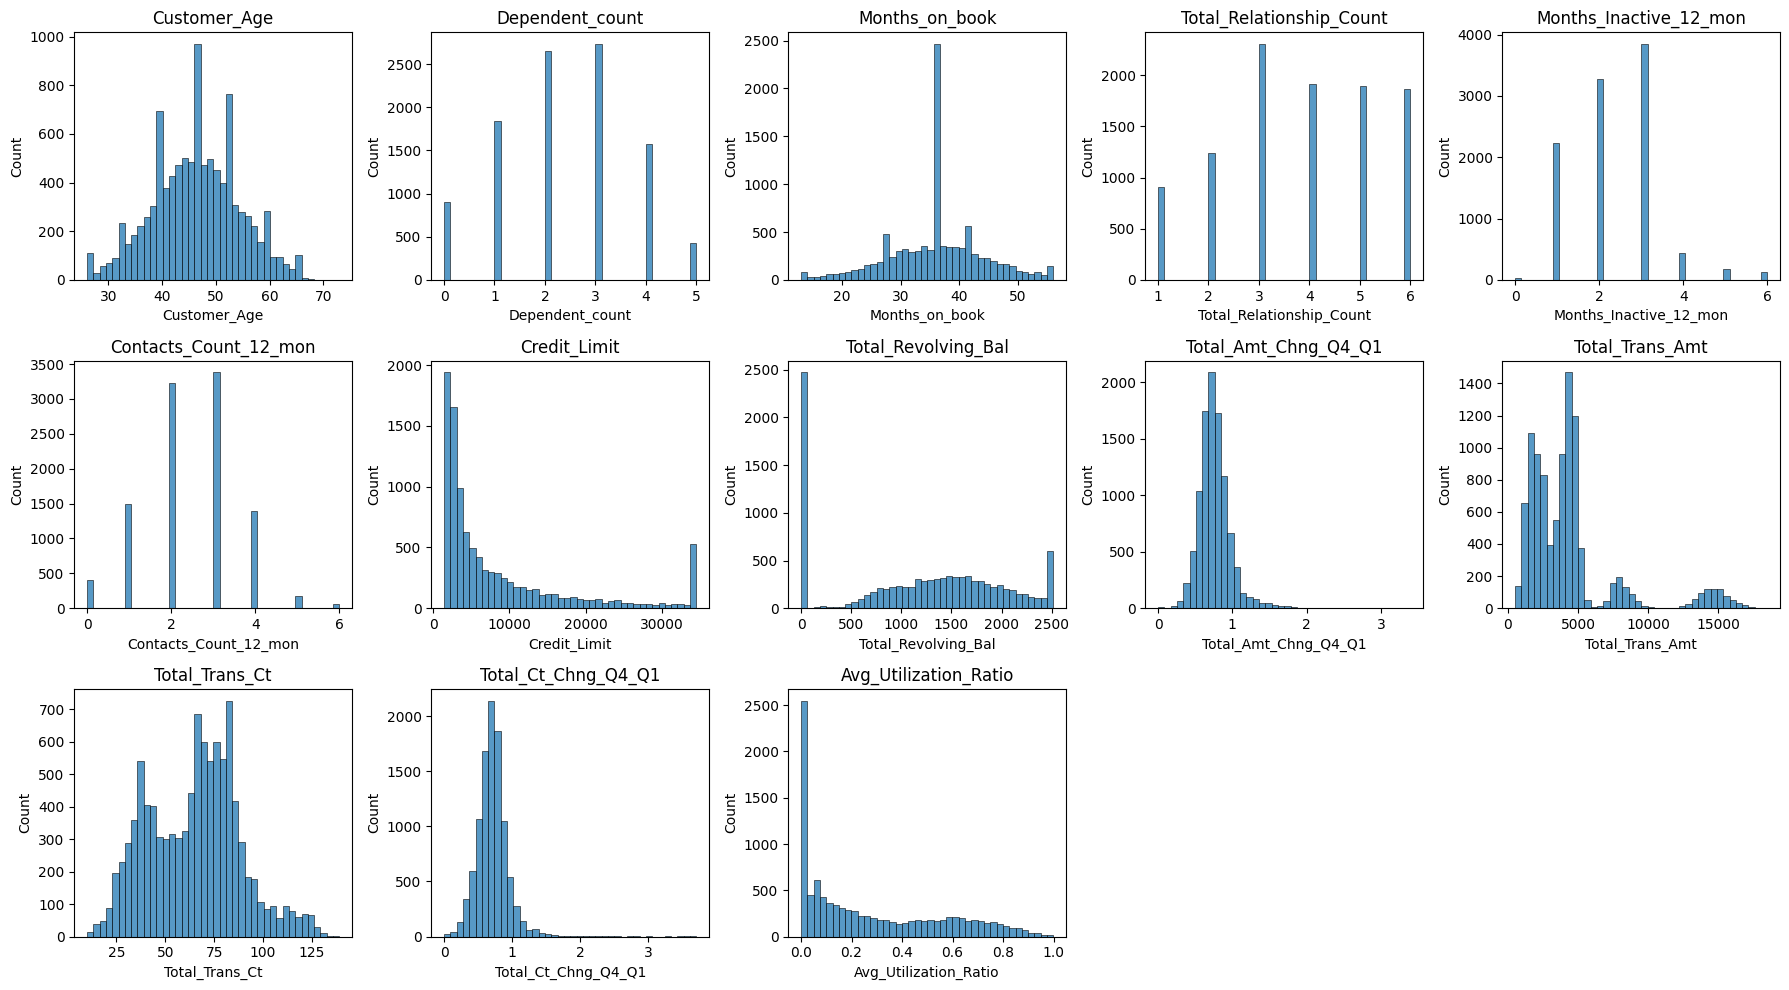

In [48]:
num = df.select_dtypes(include="number").columns.tolist()

fig, axes = plt.subplots(3, 5, figsize=(18, 10))
for ax, c in zip(axes.ravel(), num):
    sns.histplot(df[c], bins=40, ax=ax)
    ax.set_title(c)
for ax in axes.ravel()[len(num):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

Notam-se muitos zeros no saldo rotativo e no uso do limite. Contando:

In [49]:
print("Percentual de zeros em cada coluna numérica:")
(df[num] == 0).mean().mul(100).round(1)

Percentual de zeros em cada coluna numérica:


,0
Customer_Age,0.0
Dependent_count,8.9
Months_on_book,0.0
Total_Relationship_Count,0.0
Months_Inactive_12_mon,0.3
Contacts_Count_12_mon,3.9
Credit_Limit,0.0
Total_Revolving_Bal,24.4
Total_Amt_Chng_Q4_Q1,0.0
Total_Trans_Amt,0.0


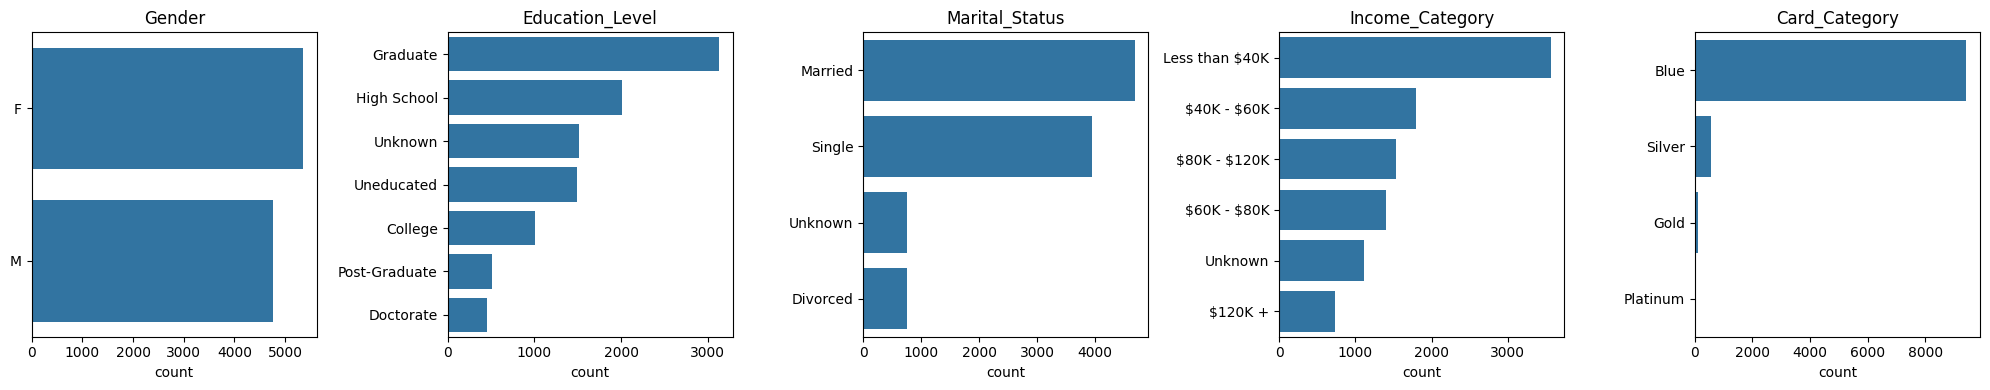

In [50]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, c in zip(axes, ["Gender", "Education_Level", "Marital_Status", "Income_Category", "Card_Category"]):
    sns.countplot(y=df[c], order=df[c].value_counts().index, ax=ax)
    ax.set_title(c)
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Leitura dos histogramas:**

- **`Customer_Age`**: formato de sino, concentrada entre 40 e 55 anos.
- **`Months_on_book`**: também em sino, mas com um **pico enorme em 36 meses** (investigado na 4.2).
- **`Dependent_count`, `Total_Relationship_Count`, `Months_Inactive_12_mon`, `Contacts_Count_12_mon`**: são **discretas** (poucos valores inteiros). A maioria dos clientes ficou de 1 a 3 meses inativa e teve de 2 a 3 contatos com o banco.
- **`Credit_Limit`**: cauda longa à direita, com uma **barra isolada no valor máximo**.
- **`Total_Revolving_Bal`** e **`Avg_Utilization_Ratio`**: **24,4% dos clientes têm zero**, ou seja, pagam a fatura inteira e não usam o crédito rotativo. É o mesmo grupo nas duas colunas. Há também uma barra no valor máximo do saldo.
- **`Total_Trans_Amt`**: **três blocos separados** de gasto anual: até ~5 mil (a grande maioria), de ~7 a 10 mil e de ~12 a 17 mil, com quase ninguém entre eles. É uma primeira pista de perfis diferentes de gasto, a conferir no t-SNE e nos clusters.
- **`Total_Trans_Ct`**: dois picos, perto de 40 e de 75 transações.
- **`Total_Amt_Chng_Q4_Q1`** e **`Total_Ct_Chng_Q4_Q1`**: concentradas entre 0,5 e 1 (o cliente gastou um pouco menos no 4º trimestre que no 1º), com poucos valores acima de 2.
- **Categóricas**: a grande maioria tem cartão **Blue** (93%), o que deixa `Card_Category` quase constante. A faixa de renda mais comum é **abaixo de US$ 40K**, com 35% dos clientes: é a maior faixa, mas não a maioria. Gold e Platinum somam só 136 clientes.

### 4.2 Boxplots e valores extremos

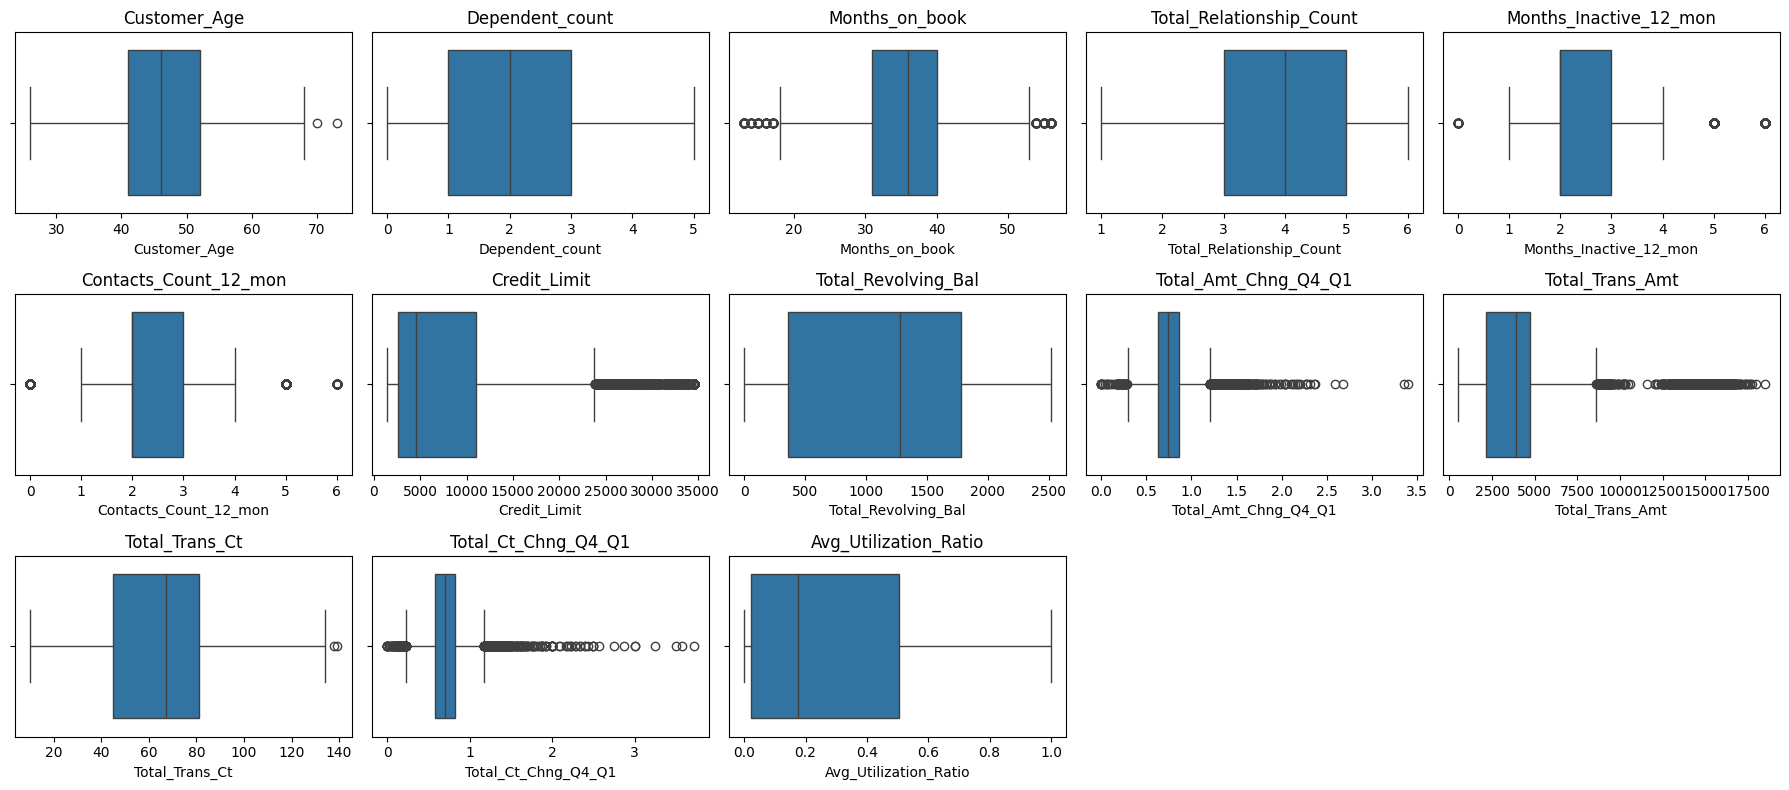

In [51]:
fig, axes = plt.subplots(3, 5, figsize=(18, 8))
for ax, c in zip(axes.ravel(), num):
    sns.boxplot(x=df[c], ax=ax)
    ax.set_title(c)
for ax in axes.ravel()[len(num):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

Investigando os extremos das colunas numéricas:

In [52]:
print("Os 5 maiores limites:", sorted(df["Credit_Limit"].unique().tolist())[-5:])
print("Clientes com limite = 34.516:", (df["Credit_Limit"] == 34516).sum())
print("Os 5 menores limites:", sorted(df["Credit_Limit"].unique().tolist())[:5])
print("Clientes com limite = 1.438,3:", (df["Credit_Limit"] == 1438.3).sum())

print("\nOs 5 menores saldos rotativos:", sorted(df["Total_Revolving_Bal"].unique().tolist())[:5])
print("Os 5 maiores saldos rotativos:", sorted(df["Total_Revolving_Bal"].unique().tolist())[-5:])
print("Clientes com saldo = 2.517:", (df["Total_Revolving_Bal"] == 2517).sum())

Os 5 maiores limites: [34198.0, 34427.0, 34458.0, 34496.0, 34516.0]
Clientes com limite = 34.516: 508
Os 5 menores limites: [1438.3, 1439.0, 1440.0, 1441.0, 1442.0]
Clientes com limite = 1.438,3: 507

Os 5 menores saldos rotativos: [0, 132, 134, 145, 154]
Os 5 maiores saldos rotativos: [2511, 2512, 2513, 2514, 2517]
Clientes com saldo = 2.517: 508


In [53]:
print("Clientes por tempo de relacionamento (33 a 39 meses):")
print(df["Months_on_book"].value_counts().sort_index().loc[33:39].to_string())
print(f"\n36 meses representa {(df['Months_on_book'] == 36).mean():.1%} da base")

Clientes por tempo de relacionamento (33 a 39 meses):
Months_on_book
33     305
34     353
35     317
36    2463
37     358
38     347
39     341

36 meses representa 24.3% da base


In [54]:
print("Taxa de cancelamento por número de contatos com o banco:")
contatos = df.groupby("Contacts_Count_12_mon")["Attrition_Flag"].agg(
    clientes="size", pct_cancelou=lambda s: (s == "Attrited Customer").mean() * 100)
contatos.round(1)

Taxa de cancelamento por número de contatos com o banco:


,clientes,pct_cancelou
Contacts_Count_12_mon,,
0,399,1.8
1,1499,7.2
2,3227,12.5
3,3380,20.1
4,1392,22.6
5,176,33.5
6,54,100.0


In [55]:
print("Maiores variações de valor gasto (Q4/Q1):", df["Total_Amt_Chng_Q4_Q1"].nlargest(5).tolist())
print("Maiores variações de nº de transações (Q4/Q1):", df["Total_Ct_Chng_Q4_Q1"].nlargest(5).tolist())
print("Clientes com variação de transações > 2:", (df["Total_Ct_Chng_Q4_Q1"] > 2).sum())
print("\nIdades mais altas:")
print(df["Customer_Age"].value_counts().sort_index().tail(6).to_string())

Maiores variações de valor gasto (Q4/Q1): [3.397, 3.355, 2.675, 2.594, 2.368]
Maiores variações de nº de transações (Q4/Q1): [3.714, 3.571, 3.5, 3.25, 3.0]
Clientes com variação de transações > 2: 26

Idades mais altas:
Customer_Age
65    101
66      2
67      4
68      2
70      1
73      1


In [56]:
# O teto do limite (34.516) é coerente com a renda declarada?
no_teto = df["Credit_Limit"].eq(34516).map({True: "no teto (34.516)", False: "demais clientes"})
print("Renda declarada (% de cada linha):")
(pd.crosstab(no_teto, df["Income_Category"], normalize="index") * 100).round(1)

Renda declarada (% de cada linha):


Income_Category,$120K +,$40K - $60K,$60K - $80K,$80K - $120K,Less than $40K,Unknown
Credit_Limit,,,,,,
demais clientes,5.4,18.6,14.1,13.7,37.0,11.1
no teto (34.516),40.0,0.0,9.6,42.3,0.0,8.1


- **`Credit_Limit` = 34.516** (508 clientes) e **= 1.438,3** (507 clientes): os dois extremos têm centenas de clientes exatamente no mesmo valor, enquanto os valores vizinhos aparecem uma ou duas vezes cada. Parecem **teto e piso** do limite, como o `capital-gain = 99999` da Adult. O dado é coerente: na tabela acima, **82%** de quem está no teto declara renda acima de US$ 80K, contra 19% no restante da base. Ele só está "cortado" no valor máximo.
- **`Total_Revolving_Bal`**: além do teto em 2.517 (508 clientes), há um **salto de 0 direto para 132**, sem nenhum valor entre eles. Quem tem saldo rotativo tem pelo menos 132.
- **`Months_on_book` = 36**: 2.463 clientes (24% da base), contra ~350 nos meses vizinhos. Esse pico não segue o formato de sino do resto. Pode ser um **valor padrão** usado quando a data de entrada era desconhecida.
- **`Contacts_Count_12_mon` = 6**: são só 54 clientes, mas **100% deles cancelaram**. A taxa de cancelamento sobe junto com o número de contatos (1,8% com zero contatos, 33,5% com 5). Muitos contatos parecem sinal de insatisfação.
- **Variações Q4/Q1** acima de 2 (até 3,7) e **idades** acima de 65 são raras, mas possíveis.

Decisão: **manter os extremos**. São casos raros, mas válidos, e alguns (como os clientes com 6 contatos) são justamente os mais interessantes para o problema. O pico de 36 meses fica registrado como suspeito: se `Months_on_book` for usada no agrupamento, vale lembrar que 1 em cada 4 clientes pode ter esse valor por padrão. Para que as escalas diferentes não dominem as distâncias, na etapa de agrupamento as colunas serão padronizadas, e as de cauda longa (`Credit_Limit`, `Total_Trans_Amt`) podem ser "achatadas" com `np.log1p`, como foi feito com o `capital-gain`.

## **Tópico 4: Construam os clusters**


**Escolha do algoritmo**

O **K-Means** foi escolhido por quatro motivos porque as variáveis de comportamento são quantitativas. Os centroides são fáceis de interpretar como perfis. O algoritmo é eficiente para cerca de 10 mil clientes. E todo cliente fica em um segmento, o que garante uma estratégia para a carteira inteira.

Também consideramos os outros algoritmos da disciplina:
- **Hierárquico:** precisa da matriz de distâncias entre todos os pares (oque daria muitos pares para 10.127 clientes), e um dendrograma com 10 mil folhas não é legível.
- **DBSCAN:** procura regiões densas separadas por vazios, então o DBSCAN tenderia a formar um grande grupo mais ruído e deixaria clientes sem segmento. Ele seria mais útil para achar anomalias do que para segmentar a carteira.

Para lidar com as limitações do K-Means, adotamos quatro cuidados:
- as variáveis foram padronizadas;
- as de cauda longa (`Credit_Limit`, `Total_Trans_Amt`) foram transformadas com `log1p`;
- o número de clusters (k) foi escolhido com várias métricas (cotovelo, silhueta, Davies-Bouldin, Calinski-Harabasz);
- os valores extremos foram mantidos, sabendo que eles puxam os centroides (ver Tópico 5).

**Variáveis**

Entram no agrupamento 12 variáveis:
- **uso do cartão:** `Total_Trans_Amt`, `Total_Trans_Ct`, `Total_Amt_Chng_Q4_Q1`, `Total_Ct_Chng_Q4_Q1`, `Months_Inactive_12_mon`;
- **crédito:** `Credit_Limit`, `Total_Revolving_Bal`, `Avg_Utilization_Ratio`;
- **relacionamento:** `Total_Relationship_Count`, `Months_on_book`, `Contacts_Count_12_mon`;
- **idade:** `Customer_Age`, como variável de ciclo de vida.

`CLIENTNUM`, as colunas Naive Bayes e `Avg_Open_To_Buy` já foram removidas na seção 3. Também ficam **fora** do agrupamento:
- os dados cadastrais `Dependent_count`, `Education_Level` e `Marital_Status`, porque não descrevem o uso do cartão;
- `Card_Category`, que é quase constante (93% Blue);
- `Income_Category` e `Gender`, pela inconsistência da seção 2.2;
- o `Attrition_Flag`.

Essas variáveis são usadas **apenas para descrever** os clusters. O `Attrition_Flag` também serve para comparar a taxa de cancelamento de cada grupo com a da base (16,1%).

**Estratégia**

1. **Visualização exploratória com t-SNE:** projeta as variáveis padronizadas em 2D para ver se existem agrupamentos naturais. O t-SNE serve só para olhar. Ele não preserva distâncias globais, então não é entrada do K-Means nem das métricas.
2. **Cenário A, sem redução:** o K-Means usa as 12 variáveis padronizadas.
3. **Cenário B, com PCA:** o K-Means usa os componentes principais que retêm pelo menos **90%** da variância. O objetivo é testar se, **com menos colunas, os grupos se mantêm**. O PCA descarta as direções de pouca variância (ruído). Atenção: sem branqueamento, o PCA apenas gira os eixos. Ele junta variáveis correlacionadas (como `Customer_Age` e `Months_on_book`) num mesmo componente, mas **não diminui o peso delas** na distância.

Os clusters dos dois cenários também são projetados no t-SNE, para comparar visualmente.

**Medidas de avaliação**

* **Inércia (WCSS):** método do cotovelo.
* **Silhueta:** quanto cada cliente está no grupo certo (maior é melhor; de −1 a 1).
* **Davies-Bouldin:** cada grupo contra o vizinho mais parecido (menor é melhor).
* **Calinski-Harabasz:** separação ÷ espalhamento (maior é melhor).
* **ARI (Rand ajustado):** concordância entre dois agrupamentos (cenário A × B e estabilidade entre execuções).
* **Taxa de cancelamento por grupo:** critério de **negócio**, externo. O `Attrition_Flag` não forma os grupos, só os avalia.

Silhueta, Davies-Bouldin e Calinski-Harabasz **só se comparam no mesmo espaço** (slhuetas de espaços diferentes não se comparam diretamente). Por isso, os cenários A e B são comparados com as métricas calculadas nas mesmas 12 variáveis padronizadas.

### Padronização das variáveis

In [57]:
# Pré-processamento
from sklearn.preprocessing import StandardScaler

# Redução de dimensionalidade
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Agrupamento
from sklearn.cluster import KMeans

# Métricas de avaliação dos clusters
from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score
)

In [58]:
# Variáveis que entram no agrupamento (comportamento, crédito e relacionamento)
vars_cluster = [
    "Customer_Age", "Months_on_book", "Total_Relationship_Count",
    "Months_Inactive_12_mon", "Contacts_Count_12_mon",
    "Credit_Limit", "Total_Revolving_Bal", "Avg_Utilization_Ratio",
    "Total_Trans_Amt", "Total_Trans_Ct",
    "Total_Amt_Chng_Q4_Q1", "Total_Ct_Chng_Q4_Q1",
]

X = df[vars_cluster].copy()

# "Achatando" as colunas de cauda longa (seção 4.2)
for c in ["Credit_Limit", "Total_Trans_Amt"]:
    X[c] = np.log1p(X[c])

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=vars_cluster)

print("Variáveis no agrupamento:", len(vars_cluster))
X_scaled.describe().T[["mean", "std"]].round(2)

Variáveis no agrupamento: 12


,mean,std
Customer_Age,0.0,1.0
Months_on_book,-0.0,1.0
Total_Relationship_Count,-0.0,1.0
Months_Inactive_12_mon,0.0,1.0
Contacts_Count_12_mon,-0.0,1.0
Credit_Limit,-0.0,1.0
Total_Revolving_Bal,-0.0,1.0
Avg_Utilization_Ratio,0.0,1.0
Total_Trans_Amt,-0.0,1.0
Total_Trans_Ct,-0.0,1.0


### 1. Visualização exploratória com t-SNE





 A entrada é `X_scaled`, as mesmas variáveis padronizadas que vão para o K-Means. O `Attrition_Flag` **não entra** e serve só para colorir o gráfico.


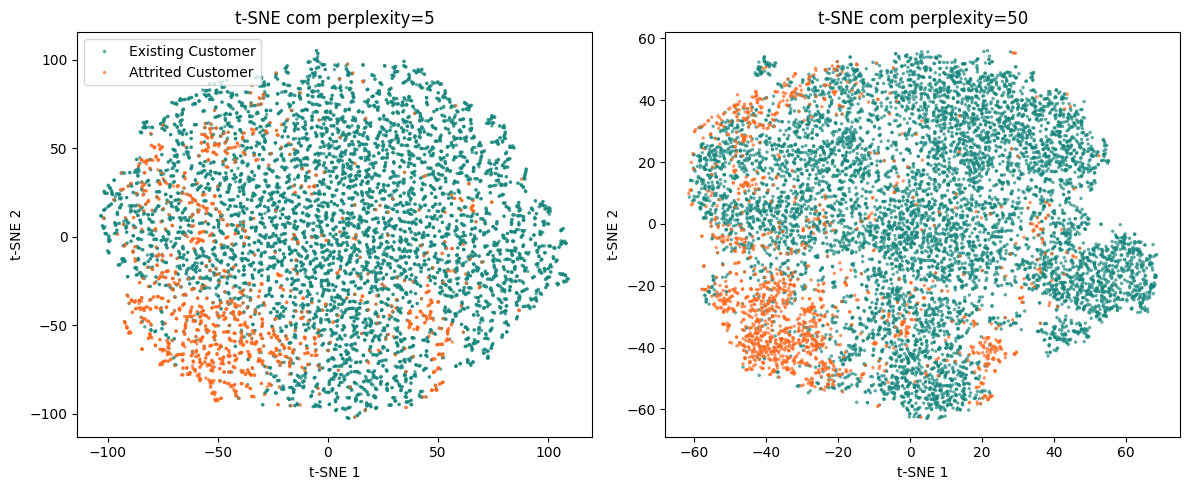

In [59]:
cores = {"Existing Customer": "#16867C", "Attrited Customer": "#FF671D"}
situacao = df["Attrition_Flag"].to_numpy()                          # mesma ordem das linhas de X_scaled
ordem = np.argsort(situacao == "Attrited Customer", kind="stable")  # só para desenhar quem cancelou por cima

fig, eixos = plt.subplots(1, 2, figsize=(12, 5))

for perplexidade, ax in zip([5, 50], eixos):
    T = TSNE(n_components=2, perplexity=perplexidade, random_state=42).fit_transform(X_scaled)
    sns.scatterplot(x=T[ordem, 0], y=T[ordem, 1], hue=situacao[ordem], hue_order=list(cores), palette=cores,
                    s=6, alpha=0.7, linewidth=0, ax=ax, legend=(perplexidade == 5))
    ax.set(title=f"t-SNE com perplexity={perplexidade}", xlabel="t-SNE 1", ylabel="t-SNE 2")

plt.tight_layout()
plt.show()

In [60]:
tsne_df = pd.DataFrame(T, columns=["tSNE_1", "tSNE_2"])

O Attrition_Flag não entrou no t-SNE, mas os laranja se concentram em uma região (embaixo, à esquerda) e em algumas ilhas pequenas, por exemplo perto de (20, -45) e no alto à esquerda. Ou seja, clientes com comportamento parecido tendem a ter o mesmo destino.

### 2. K-Means sem redução

In [61]:
# as 12 variáveis do agrupamento, já padronizadas
X_kmeans = X_scaled
print("Colunas:", len(X_kmeans.columns), "| linhas:", len(X_kmeans))
X_kmeans.describe().round(2).T


Colunas: 12 | linhas: 10127


,count,mean,std,min,25%,50%,75%,max
Customer_Age,10127.0,0.0,1.0,-2.54,-0.66,-0.04,0.71,3.33
Months_on_book,10127.0,-0.0,1.0,-2.87,-0.62,0.01,0.51,2.51
Total_Relationship_Count,10127.0,-0.0,1.0,-1.81,-0.52,0.12,0.76,1.41
Months_Inactive_12_mon,10127.0,0.0,1.0,-2.32,-0.34,-0.34,0.65,3.62
Contacts_Count_12_mon,10127.0,-0.0,1.0,-2.22,-0.41,-0.41,0.49,3.20
Credit_Limit,10127.0,-0.0,1.0,-1.43,-0.81,-0.19,0.76,1.98
Total_Revolving_Bal,10127.0,-0.0,1.0,-1.43,-0.99,0.14,0.76,1.66
Avg_Utilization_Ratio,10127.0,0.0,1.0,-1.00,-0.91,-0.36,0.83,2.63
Total_Trans_Amt,10127.0,-0.0,1.0,-2.95,-0.75,0.16,0.46,2.54
Total_Trans_Ct,10127.0,-0.0,1.0,-2.34,-0.85,0.09,0.69,3.16


In [62]:
inercia = []
silhueta = []
ks = range(2, 11)
for k in ks:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_kmeans)
    inercia.append(kmeans.inertia_)
    silhueta.append(silhouette_score(X_kmeans, kmeans.labels_))
    print(k, round(kmeans.inertia_, 1), round(silhueta[-1], 3))


2 107530.9 0.115
3 96564.0 0.123
4 89961.9 0.119
5 84799.9 0.123
6 80422.3 0.116
7 77085.8 0.115
8 74098.0 0.118
9 71882.3 0.116
10 70219.8 0.114


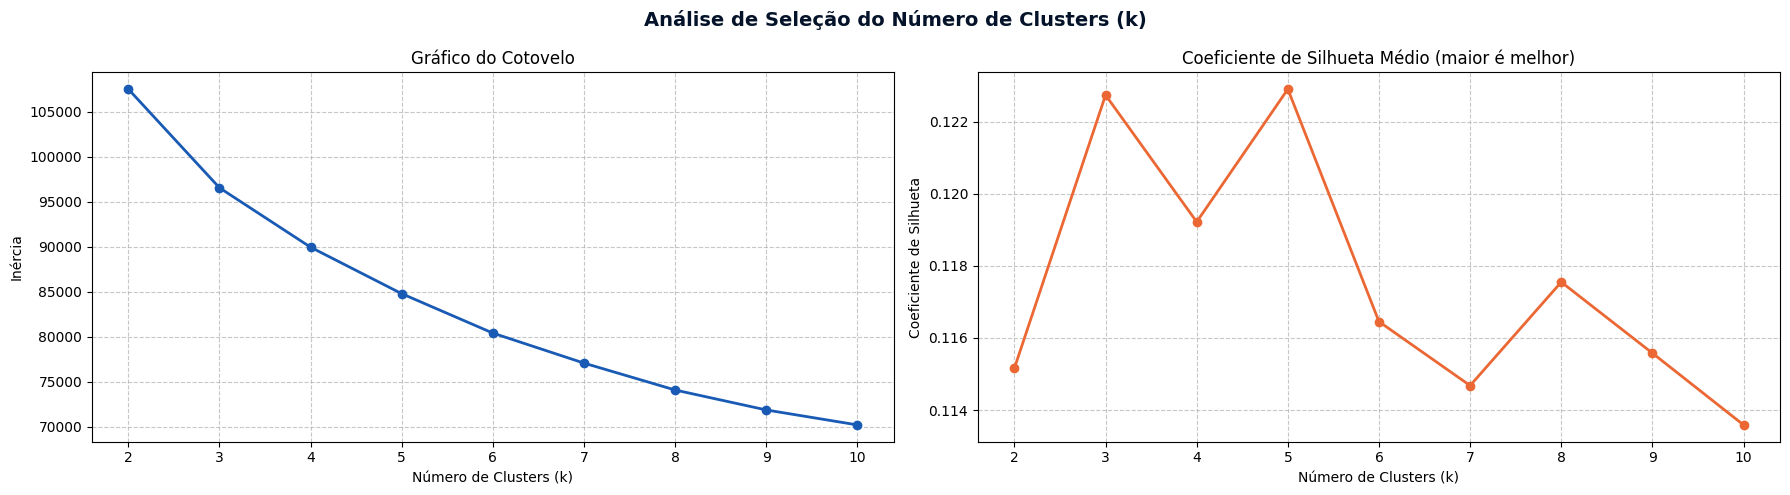

In [63]:
# Método do Cotovelo, Coeficiente de Silhueta lado a lado
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 5))

# Gráfico 1: Inércia (Método do Cotovelo)
ax1.plot(ks, inercia, marker='o', color='#195AB4', lw=2)
ax1.set_xlabel('Número de Clusters (k)')
ax1.set_ylabel('Inércia')
ax1.set_title('Gráfico do Cotovelo')
ax1.set_xticks(ks)
ax1.grid(True, linestyle='--', alpha=0.7)

# Gráfico 2: Coeficiente de Silhueta
ax2.plot(ks, silhueta, marker='o', color='#EB6834', lw=2)
ax2.set_xlabel('Número de Clusters (k)')
ax2.set_ylabel('Coeficiente de Silhueta')
ax2.set_title('Coeficiente de Silhueta Médio (maior é melhor)')
ax2.set_xticks(ks)
ax2.grid(True, linestyle='--', alpha=0.7)

plt.suptitle('Análise de Seleção do Número de Clusters (k)', fontsize=14, fontweight='bold', color='#05132A')
plt.tight_layout()
plt.show()

**Leitura do cotovelo e da silhueta (cenário A).** A inércia cai de forma suave, sem um "cotovelo" nítido. A queda é de 10,2% de k = 2 para 3, de 6,8% de 3 para 4, de 5,7% de 4 para 5 e depois vai diminuindo aos poucos (5,2%, 4,1%, 3,9%…). A curva só começa a se achatar entre k = 3 e k = 5. A silhueta fica praticamente constante (0,114 a 0,123), com os maiores valores empatados em **k = 3 e k = 5**. Por isso, a comparação detalhada a seguir fica em **k = 3, 4 e 5**: é a faixa da dobra e dos maiores valores de silhueta.

Cenário A: K-Means sobre 12 variáveis padronizadas
Taxa de cancelamento da base: 16.1%


,Silhueta (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑),Menor cluster (% base) (↑),Maior churn (%) (↑),Menor churn (%) (↓),Amplitude churn (p.p.) (↑)
k,,,,,,,
3,0.123,2.249,"1,308",20.7,26.1,8.2,17.9
4,0.119,2.140,"1,184",18.4,31.2,7.9,23.2
5,0.123,2.052,"1,096",9.1,28.6,3.2,25.5


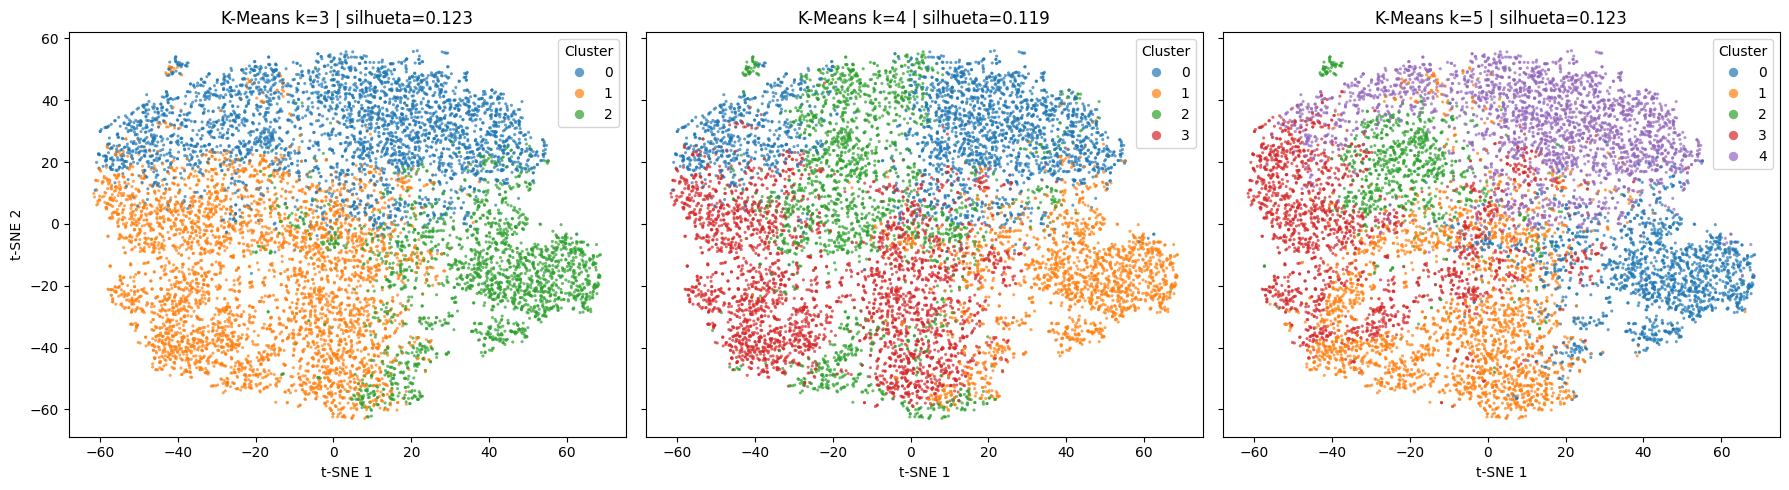

In [64]:
# Cancelamento só entra para AVALIAR os grupos, não para formá-los
cancelou = (df["Attrition_Flag"] == "Attrited Customer").to_numpy()
taxa_base = cancelou.mean()
ks_teste = [3, 4, 5]

# Direção de cada indicador ("max" = quanto maior, melhor; "min" = quanto menor, melhor) e formato
indicadores = {
    "Silhueta (↑)":                ("max", "{:.3f}"),
    "Davies-Bouldin (↓)":          ("min", "{:.3f}"),
    "Calinski-Harabasz (↑)":       ("max", "{:,.0f}"),
    "Menor cluster (% base) (↑)":  ("max", "{:.1f}"),
    "Maior churn (%) (↑)":         ("max", "{:.1f}"),
    "Menor churn (%) (↓)":         ("min", "{:.1f}"),
    "Amplitude churn (p.p.) (↑)":  ("max", "{:.1f}"),
}

def avaliar_k(X, ks):
    """Roda o K-Means para cada k e devolve os modelos e a tabela de indicadores."""
    modelos, resultados = {}, []
    for k in ks:
        km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
        rotulos = km.labels_
        modelos[k] = km
        tamanhos = np.bincount(rotulos)
        churn_cluster = pd.Series(cancelou).groupby(rotulos).mean()
        resultados.append({
            "k": k,
            "Silhueta (↑)": silhouette_score(X, rotulos),
            "Davies-Bouldin (↓)": davies_bouldin_score(X, rotulos),
            "Calinski-Harabasz (↑)": calinski_harabasz_score(X, rotulos),
            "Menor cluster (% base) (↑)": tamanhos.min() / len(rotulos) * 100,
            "Maior churn (%) (↑)": churn_cluster.max() * 100,
            "Menor churn (%) (↓)": churn_cluster.min() * 100,
            "Amplitude churn (p.p.) (↑)": (churn_cluster.max() - churn_cluster.min()) * 100,
        })
    return modelos, pd.DataFrame(resultados).set_index("k")

def estilizar(tabela):
    """Formata a tabela e pinta de verde o melhor k em cada coluna."""
    estilo = tabela.style.format({col: fmt for col, (_, fmt) in indicadores.items()})
    for col, (direcao, _) in indicadores.items():
        destacar = estilo.highlight_max if direcao == "max" else estilo.highlight_min
        estilo = destacar(subset=[col], color="#c6efce")
    return estilo

modelos, comparacao = avaliar_k(X_kmeans, ks_teste)

print(f"Cenário A: K-Means sobre {X_kmeans.shape[1]} variáveis padronizadas")
print(f"Taxa de cancelamento da base: {taxa_base:.1%}")
display(estilizar(comparacao))

# Clusters projetados no t-SNE (perplexity=50, calculado acima)
fig, eixos = plt.subplots(1, len(ks_teste), figsize=(18, 5), sharex=True, sharey=True)
for ax, k in zip(eixos, ks_teste):
    sns.scatterplot(x=tsne_df["tSNE_1"], y=tsne_df["tSNE_2"], hue=modelos[k].labels_,
                    palette="tab10", s=5, alpha=0.7, linewidth=0, ax=ax)
    ax.set(title=f"K-Means k={k} | silhueta={comparacao.loc[k, 'Silhueta (↑)']:.3f}",
           xlabel="t-SNE 1", ylabel="t-SNE 2")
    ax.legend(title="Cluster", markerscale=3)
plt.tight_layout()
plt.show()

**Leitura da tabela (cenário A).**
- a **silhueta** empata entre k = 3 e k = 5 (0,123);
- o **Davies-Bouldin** melhora a cada k e favorece **k = 5** (2,052);
- o **Calinski-Harabasz** favorece **k = 3**.


### 3. K-Means com PCA

O PCA é aplicado sobre as mesmas 12 variáveis padronizadas. Primeiro vemos quanta variância cada componente explica. Depois ficamos com o menor número de componentes que retém pelo menos **90%**.

Componentes necessários para 90% da variância: 8 de 12
Variância retida com 8 componentes: 91.4%


,Variância explicada (%),Variância acumulada (%)
PC1,18.1,18.1
PC2,15.3,33.4
PC3,14.8,48.2
PC4,11.3,59.5
PC5,9.0,68.5
PC6,8.2,76.7
PC7,7.7,84.5
PC8,7.0,91.4
PC9,5.0,96.5
PC10,1.8,98.2


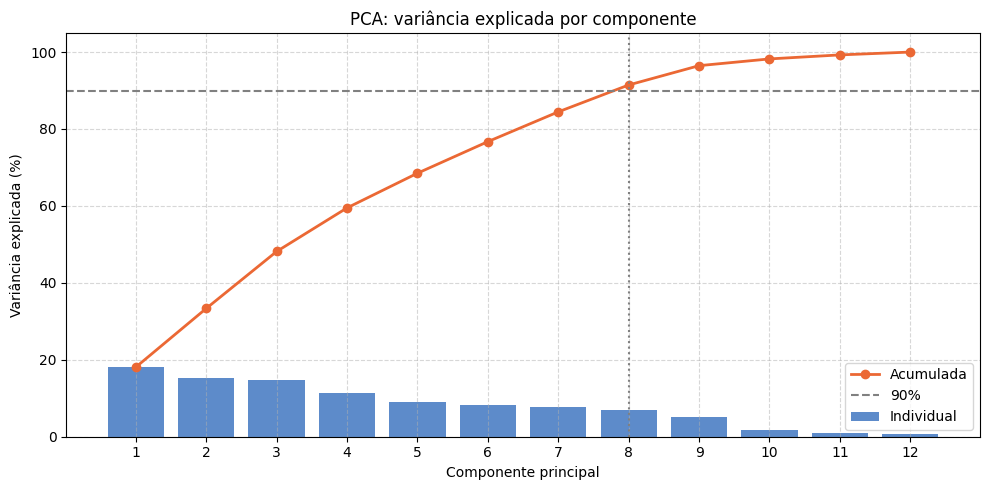

Formato de X_pca: (10127, 8)


In [65]:
# 1. PCA com todos os componentes, só para ver quanta variância cada um explica
pca_completo = PCA(random_state=42).fit(X_scaled)
var_explicada = pca_completo.explained_variance_ratio_
var_acumulada = np.cumsum(var_explicada)

# 2. Menor número de componentes que retém pelo menos 90% da variância
limite = 0.90
n_comp = int(np.argmax(var_acumulada >= limite) + 1)

print(f"Componentes necessários para {limite:.0%} da variância: {n_comp} de {X_scaled.shape[1]}")
print(f"Variância retida com {n_comp} componentes: {var_acumulada[n_comp - 1]:.1%}")

display(pd.DataFrame({
    "Variância explicada (%)": var_explicada * 100,
    "Variância acumulada (%)": var_acumulada * 100,
}, index=[f"PC{i+1}" for i in range(len(var_explicada))]).round(1))

# 3. Gráfico de variância explicada (individual + acumulada)
comps = range(1, len(var_explicada) + 1)
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(comps, var_explicada * 100, color="#195AB4", alpha=0.7, label="Individual")
ax.plot(comps, var_acumulada * 100, marker="o", color="#EB6834", lw=2, label="Acumulada")
ax.axhline(limite * 100, ls="--", color="gray", label=f"{limite:.0%}")
ax.axvline(n_comp, ls=":", color="gray")
ax.set(xlabel="Componente principal", ylabel="Variância explicada (%)",
       title="PCA: variância explicada por componente", xticks=list(comps))
ax.legend()
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# 4. PCA final com n_comp componentes -> entrada do K-Means no Cenário B
pca = PCA(n_components=n_comp, random_state=42)
X_pca = pd.DataFrame(pca.fit_transform(X_scaled),
                     columns=[f"PC{i+1}" for i in range(n_comp)])
print("Formato de X_pca:", X_pca.shape)

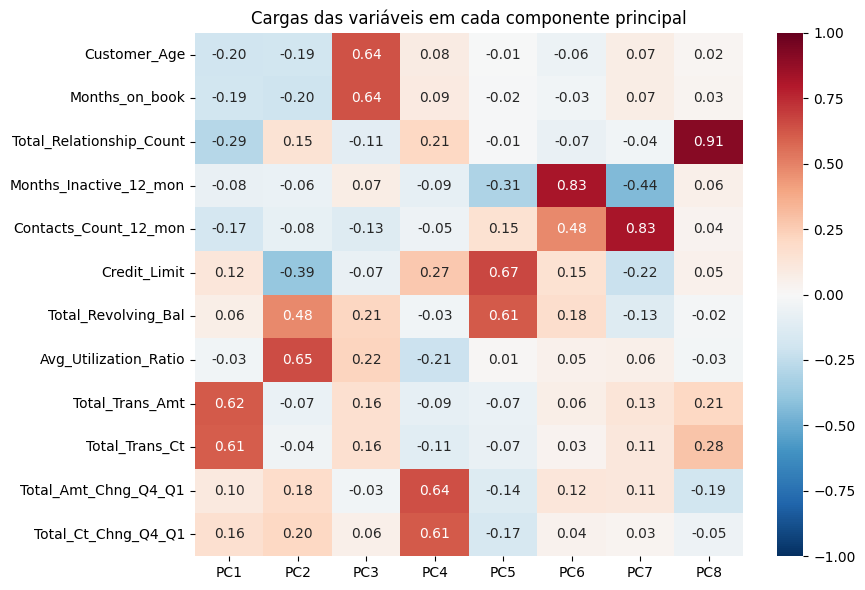

In [66]:
# Cargas (loadings): quanto cada variável pesa em cada componente
cargas = pd.DataFrame(pca.components_.T, index=vars_cluster, columns=X_pca.columns)

plt.figure(figsize=(9, 6))
sns.heatmap(cargas, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Cargas das variáveis em cada componente principal")
plt.tight_layout()
plt.show()

**Leitura do PCA.** Com 7 componentes ficamos em 84,5%, então são necessários **8 de 12** para passar de 90% (91,4%). A variância está bem espalhada: o PC1 explica só 18%. Isso indica que não há um ou dois "eixos dominantes" nos dados. As cargas permitem dar nome a cada componente:

| Componente | Variáveis com maior carga | Interpretação |
|---|---|---|
| PC1 | `Total_Trans_Amt` (0,62), `Total_Trans_Ct` (0,61) | volume de uso do cartão |
| PC2 | `Avg_Utilization_Ratio` (0,65), `Total_Revolving_Bal` (0,48), `Credit_Limit` (−0,39) | uso do crédito rotativo |
| PC3 | `Customer_Age` (0,64), `Months_on_book` (0,64) | idade / tempo de casa |
| PC4 | `Total_Amt_Chng_Q4_Q1` (0,64), `Total_Ct_Chng_Q4_Q1` (0,61) | variação do uso no 4º trimestre |
| PC5 | `Credit_Limit` (0,67), `Total_Revolving_Bal` (0,61) | tamanho do limite e do saldo |
| PC6 | `Months_Inactive_12_mon` (0,83) | inatividade |
| PC7 | `Contacts_Count_12_mon` (0,83) | contatos com o banco |
| PC8 | `Total_Relationship_Count` (0,91) | número de produtos |

Os pares correlacionados caem no mesmo componente (idade e tempo de casa no PC3; valor e quantidade de transações no PC1). Mas, como o PCA não foi branqueado, a variância desses pares continua pesando na distância. O que sai são os 4 últimos componentes, com 8,6% da variância.

2 97137.5 | silhueta nos PCs: 0.125 | nas 12 variáveis: 0.115
3 86218.5 | silhueta nos PCs: 0.135 | nas 12 variáveis: 0.123
4 79642.7 | silhueta nos PCs: 0.131 | nas 12 variáveis: 0.119
5 74495.0 | silhueta nos PCs: 0.137 | nas 12 variáveis: 0.122
6 70130.7 | silhueta nos PCs: 0.131 | nas 12 variáveis: 0.116
7 66848.4 | silhueta nos PCs: 0.128 | nas 12 variáveis: 0.113
8 63820.4 | silhueta nos PCs: 0.133 | nas 12 variáveis: 0.118
9 61615.0 | silhueta nos PCs: 0.131 | nas 12 variáveis: 0.115
10 59880.0 | silhueta nos PCs: 0.132 | nas 12 variáveis: 0.116


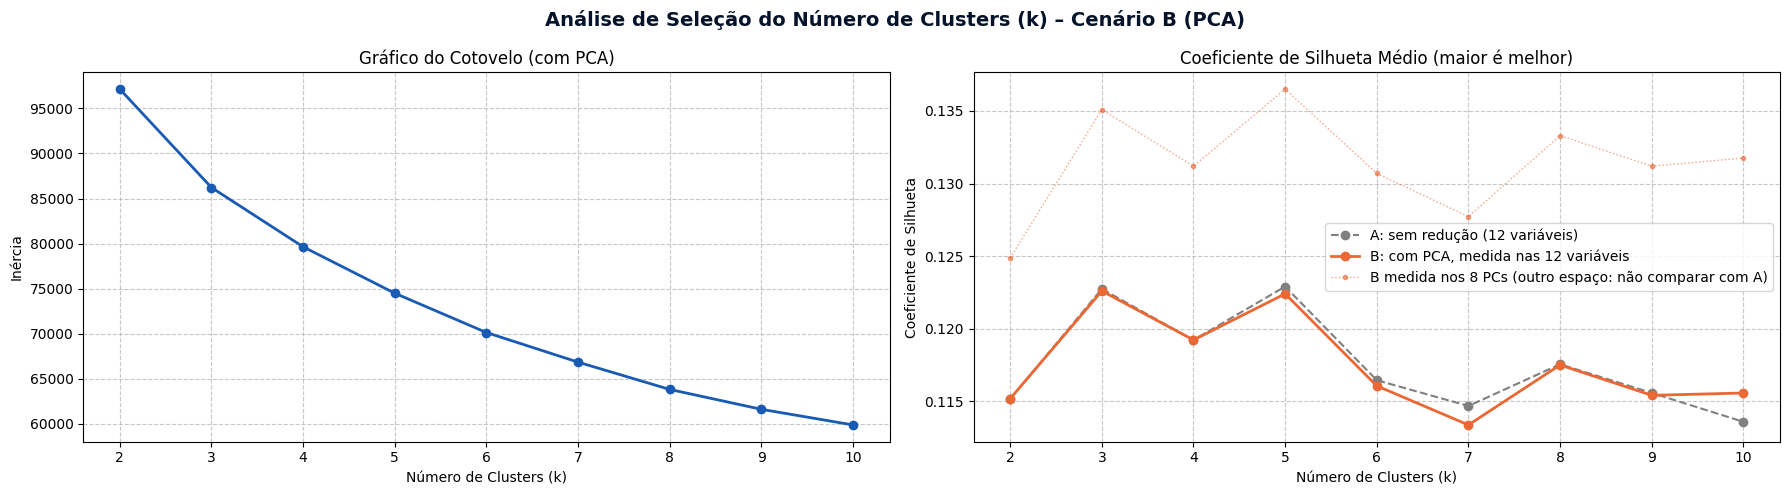

In [67]:
inercia_pca, silhueta_pca, silhueta_pca_X = [], [], []
ks = range(2, 11)

for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_pca)
    inercia_pca.append(km.inertia_)
    silhueta_pca.append(silhouette_score(X_pca, km.labels_))       # medida nos 8 PCs
    silhueta_pca_X.append(silhouette_score(X_scaled, km.labels_))  # medida nas 12 variáveis (mesmo espaço do cenário A)
    print(k, round(km.inertia_, 1), "| silhueta nos PCs:", round(silhueta_pca[-1], 3),
          "| nas 12 variáveis:", round(silhueta_pca_X[-1], 3))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 5))

# Cotovelo
ax1.plot(ks, inercia_pca, marker="o", color="#195AB4", lw=2)
ax1.set(xlabel="Número de Clusters (k)", ylabel="Inércia",
        title="Gráfico do Cotovelo (com PCA)", xticks=list(ks))
ax1.grid(True, linestyle="--", alpha=0.7)

# Silhueta: só se compara A com B no MESMO espaço
ax2.plot(ks, silhueta, marker="o", color="gray", lw=1.5, ls="--", label="A: sem redução (12 variáveis)")
ax2.plot(ks, silhueta_pca_X, marker="o", color="#EB6834", lw=2, label="B: com PCA, medida nas 12 variáveis")
ax2.plot(ks, silhueta_pca, marker=".", color="#EB6834", lw=1, ls=":", alpha=0.6,
         label="B medida nos 8 PCs (outro espaço: não comparar com A)")
ax2.set(xlabel="Número de Clusters (k)", ylabel="Coeficiente de Silhueta",
        title="Coeficiente de Silhueta Médio (maior é melhor)", xticks=list(ks))
ax2.legend()
ax2.grid(True, linestyle="--", alpha=0.7)

plt.suptitle("Análise de Seleção do Número de Clusters (k) – Cenário B (PCA)",
             fontsize=14, fontweight="bold", color="#05132A")
plt.tight_layout()
plt.show()

**Leitura (cenário B).** O cotovelo continua suave, com a mesma dobra entre k = 3 e k = 5. Medida nas mesmas 12 variáveis, a silhueta do cenário B fica **praticamente em cima** da do cenário A. Medida nos 8 PCs, ela parece um pouco maior (0,13 contra 0,12), mas isso acontece só porque as distâncias foram calculadas em outro espaço, com menos dimensões.

Cenário B: K-Means sobre 8 componentes principais
Taxa de cancelamento da base: 16.1%


,Silhueta (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑),Menor cluster (% base) (↑),Maior churn (%) (↑),Menor churn (%) (↓),Amplitude churn (p.p.) (↑)
k,,,,,,,
3,0.135,2.125,"1,462",20.8,26.3,8.0,18.3
4,0.131,1.998,"1,334",18.4,31.5,7.5,24.0
5,0.137,1.919,"1,244",8.8,30.2,3.0,27.2


Concordância A×B (ARI): k=3: 0.975 | k=4: 0.953 | k=5: 0.939


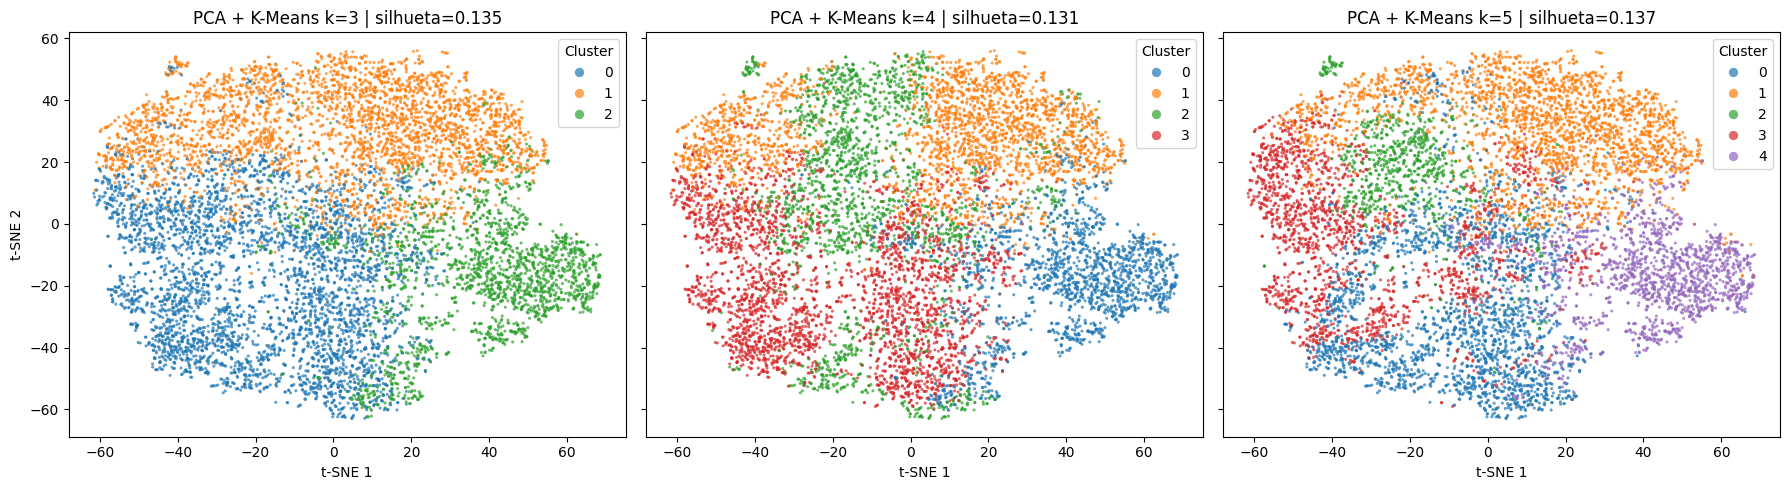

In [68]:
modelos_pca, comparacao_pca = avaliar_k(X_pca, ks_teste)

print(f"Cenário B: K-Means sobre {X_pca.shape[1]} componentes principais")
print(f"Taxa de cancelamento da base: {taxa_base:.1%}")
display(estilizar(comparacao_pca))

# Concordância com o Cenário A (1 = mesmos grupos) -> justifica o uso do PCA, não a escolha do k
ari = {k: adjusted_rand_score(modelos[k].labels_, modelos_pca[k].labels_) for k in ks_teste}
print("Concordância A×B (ARI): " + " | ".join(f"k={k}: {v:.3f}" for k, v in ari.items()))

# Clusters do Cenário B no t-SNE
fig, eixos = plt.subplots(1, len(ks_teste), figsize=(18, 5), sharex=True, sharey=True)
for ax, k in zip(eixos, ks_teste):
    sns.scatterplot(x=tsne_df["tSNE_1"], y=tsne_df["tSNE_2"], hue=modelos_pca[k].labels_,
                    palette="tab10", s=5, alpha=0.7, linewidth=0, ax=ax)
    ax.set(title=f"PCA + K-Means k={k} | silhueta={comparacao_pca.loc[k, 'Silhueta (↑)']:.3f}",
           xlabel="t-SNE 1", ylabel="t-SNE 2")
    ax.legend(title="Cluster", markerscale=3)
plt.tight_layout()
plt.show()

**Leitura da tabela (cenário B).** O padrão é o mesmo do cenário A: a silhueta empata entre k = 3 e k = 5, o Davies-Bouldin favorece k = 5 e o Calinski-Harabasz favorece k = 3. O **ARI entre A e B** fica entre 0,94 e 0,98, então os dois cenários formam praticamente **os mesmos grupos**. No t-SNE, os mapas dos dois cenários são quase idênticos.

## **Tópico 5: Avaliem os clusters gerados**

### 5.1 Comparação justa entre os cenários (mesmo espaço)
Para comparar A e B, calculamos silhueta, Davies-Bouldin e Calinski-Harabasz dos rótulos dos dois cenários **nas mesmas 12 variáveis padronizadas**.

In [69]:
# Métricas dos dois cenários medidas no MESMO espaço (12 variáveis padronizadas)
linhas = []
for k in ks_teste:
    for cenario, rotulos in [("A: sem redução", modelos[k].labels_), ("B: com PCA", modelos_pca[k].labels_)]:
        linhas.append({
            "k": k, "Cenário": cenario,
            "Silhueta (↑)": silhouette_score(X_scaled, rotulos),
            "Davies-Bouldin (↓)": davies_bouldin_score(X_scaled, rotulos),
            "Calinski-Harabasz (↑)": calinski_harabasz_score(X_scaled, rotulos),
            "ARI A×B": ari[k],
        })
mesmo_espaco = pd.DataFrame(linhas).set_index(["k", "Cenário"])
mesmo_espaco.style.format({"Silhueta (↑)": "{:.3f}", "Davies-Bouldin (↓)": "{:.3f}",
                           "Calinski-Harabasz (↑)": "{:,.0f}", "ARI A×B": "{:.3f}"})

### 5.2 Escolha do modelo final

No mesmo espaço, os dois cenários têm **as mesmas métricas** (silhueta 0,123 / 0,119 / 0,122 para k = 3 / 4 / 5 nos dois, e Davies-Bouldin e Calinski-Harabasz praticamente iguais). Os grupos também são praticamente os mesmos (ARI de 0,94 a 0,98). Ou seja, o PCA **não melhora nem piora** a separação. Ele chega aos mesmos grupos com **8 colunas em vez de 12**. Ficamos com o **cenário B (PCA)** por parcimônia, já que não houve tanta diferençasabendo que o cenário A levaria a conclusões muito próximas.

**Por que k = 5.** As métricas internas discordam:
- a silhueta empata entre k = 3 e k = 5;
- o Davies-Bouldin favorece k = 5;
- o Calinski-Harabasz favorece k = 3;
- o cotovelo não é nítido.

O critério foi a **utilidade para a retenção**. Com k = 5, o cancelamento vai de **3,0%** a **30,2%** . Com k = 3, vai de 8,0% a 26,3% (18,3 p.p.): o grupo de menor risco ainda tem 8% de cancelamento. O menor grupo de k = 5 reúne 8,8% dos clientes, tamanho suficiente para uma ação própria. O `Attrition_Flag` **não foi usado para formar** os grupos, apenas para escolher entre soluções tecnicamente empatadas.

**Qualidade dos grupos.** A silhueta fica em torno de **0,12**. Pela referência do curso, abaixo de 0,25 não há estrutura de clusters clara. Isso confirma o que o t-SNE já mostrava: a carteira é uma **massa contínua**, sem grupos naturais bem separados. Os 5 clusters são uma **partição útil para o negócio**: devem ser lidos como **perfis predominantes**, com fronteiras graduais, e não como grupos naturais. A estabilidade (5.3) e a silhueta de cada cluster (5.4) mostram até onde dá para confiar neles.

Taxa de cancelamento da base: 16.1%


,Clientes,% da base,Cancelamento (%),vs. base (x)
Cluster,,,,
C1,888,8.8,3.0,0.2
C2,"1,698",16.8,7.0,0.4
C3,"2,872",28.4,7.7,0.5
C4,"2,610",25.8,24.4,1.5
C5,"2,059",20.3,30.2,1.9


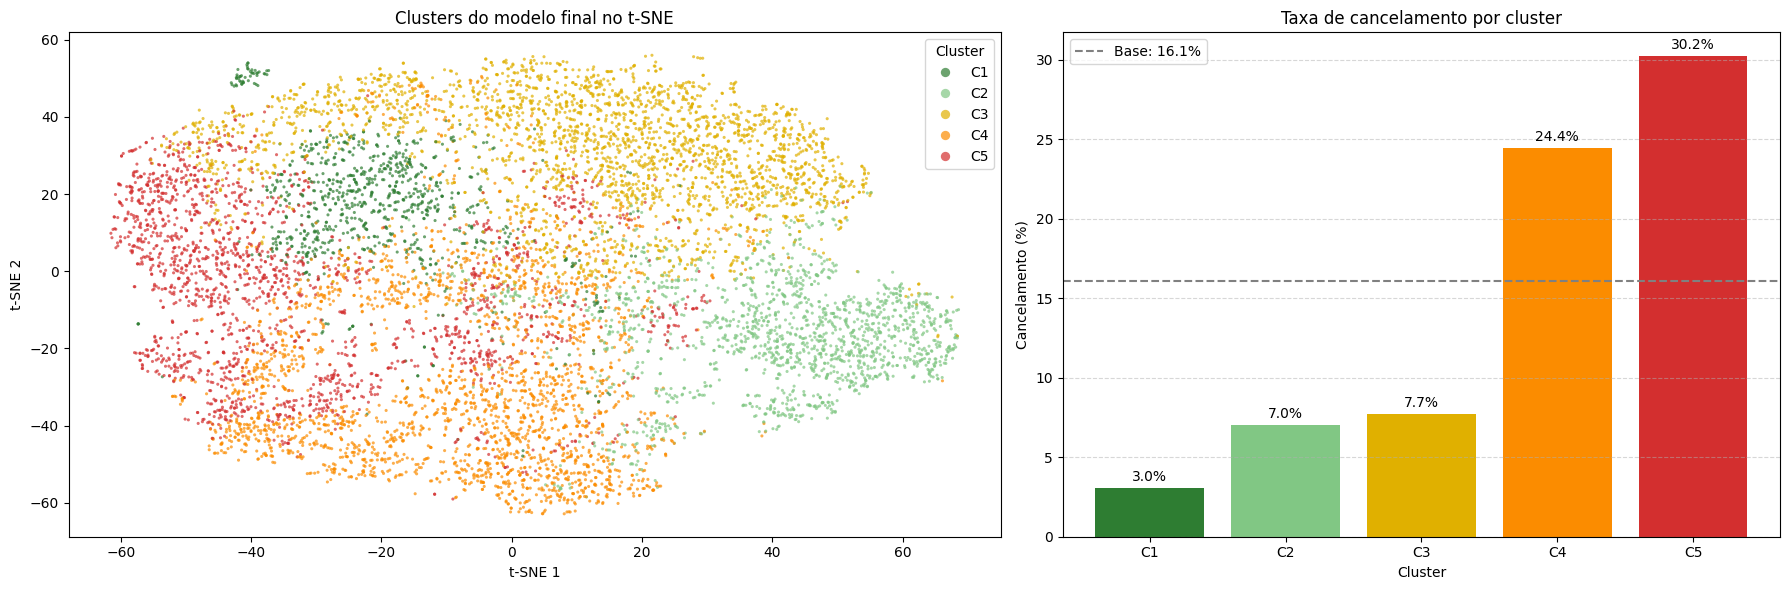

In [70]:
# Modelo final: PCA (8 componentes) + K-Means com k = 5
k_final = 5
modelo_final = modelos_pca[k_final]

# Renumera os clusters do menor para o maior cancelamento (C1 = menor risco, C5 = maior risco)
churn_por_cluster = pd.Series(cancelou).groupby(modelo_final.labels_).mean()
nova_ordem = {antigo: f"C{novo}" for novo, antigo
              in enumerate(churn_por_cluster.sort_values().index, start=1)}
df["Cluster"] = pd.Series(modelo_final.labels_).map(nova_ordem).to_numpy()
ordem_clusters = [f"C{i}" for i in range(1, k_final + 1)]

# Tamanho e cancelamento de cada cluster
resumo_final = (df.assign(cancelou=cancelou)
                .groupby("Cluster")["cancelou"]
                .agg(Clientes="size", Cancelamento="mean"))
resumo_final["% da base"] = resumo_final["Clientes"] / len(df) * 100
resumo_final["Cancelamento (%)"] = resumo_final["Cancelamento"] * 100
resumo_final["vs. base (x)"] = resumo_final["Cancelamento"] / taxa_base
resumo_final = resumo_final[["Clientes", "% da base", "Cancelamento (%)", "vs. base (x)"]]

print(f"Taxa de cancelamento da base: {taxa_base:.1%}")
display(
    resumo_final.style
    .format({"Clientes": "{:,.0f}", "% da base": "{:.1f}",
             "Cancelamento (%)": "{:.1f}", "vs. base (x)": "{:.1f}"})
    .background_gradient(subset=["Cancelamento (%)"], cmap="Oranges")
)

# Gráficos: clusters no t-SNE + cancelamento por cluster
cores_cluster = dict(zip(ordem_clusters, ["#2E7D32", "#81C784", "#E0B000", "#FB8C00", "#D32F2F"]))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [1.3, 1]})

sns.scatterplot(x=tsne_df["tSNE_1"], y=tsne_df["tSNE_2"], hue=df["Cluster"].to_numpy(),
                hue_order=ordem_clusters, palette=cores_cluster,
                s=5, alpha=0.7, linewidth=0, ax=ax1)
ax1.set(title="Clusters do modelo final no t-SNE", xlabel="t-SNE 1", ylabel="t-SNE 2")
ax1.legend(title="Cluster", markerscale=3)

barras = ax2.bar(resumo_final.index, resumo_final["Cancelamento (%)"],
                 color=[cores_cluster[c] for c in resumo_final.index])
ax2.bar_label(barras, fmt="%.1f%%", padding=3)
ax2.axhline(taxa_base * 100, ls="--", color="gray", label=f"Base: {taxa_base:.1%}")
ax2.set(title="Taxa de cancelamento por cluster", xlabel="Cluster", ylabel="Cancelamento (%)")
ax2.legend()
ax2.grid(True, axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

**Resumo do modelo final.** Os clusters foram renumerados do menor para o maior cancelamento (C1 = menor risco, C5 = maior risco). Três grupos ficam abaixo da taxa da base: **C1 (3,0%)**, **C2 (7,0%)** e **C3 (7,7%)**. Dois ficam acima: **C4 (24,4%)** e **C5 (30,2%)**. No t-SNE, C2 ocupa a ilha da direita (gasto muito alto), C5 fica à esquerda, C4 embaixo e C3 no alto. As fronteiras entre eles se misturam, como esperado pela silhueta baixa.

## **Tópico 6: Detalhamento de cada cluster**

### 6.1 Variáveis usadas no agrupamento
A tabela mostra a **mediana** de cada variável por cluster, em valores originais. O mapa de calor mostra a **média padronizada**: 0 é a média da base, e valores positivos ou negativos indicam quantos desvios-padrão o grupo fica acima ou abaixo. `Credit_Limit` e `Total_Trans_Amt` aparecem no mapa já com `log1p`.

Cluster,C1,C2,C3,C4,C5
Clientes,888,"1,698","2,872","2,610","2,059"
% da base,8.8,16.8,28.4,25.8,20.3
Cancelamento (%),3.0,7.0,7.7,24.4,30.2
% dos cancelamentos,1.7,7.3,13.6,39.2,38.2
Customer_Age,44.00,46.00,46.00,43.00,54.00
Months_on_book,36.00,36.00,36.00,34.00,42.00
Total_Relationship_Count,5.00,2.00,4.00,4.00,4.00
Months_Inactive_12_mon,2.00,2.00,2.00,2.00,3.00
Contacts_Count_12_mon,2.00,2.00,2.00,3.00,3.00
Credit_Limit,"6,870","11,418","2,616","5,300","6,778"


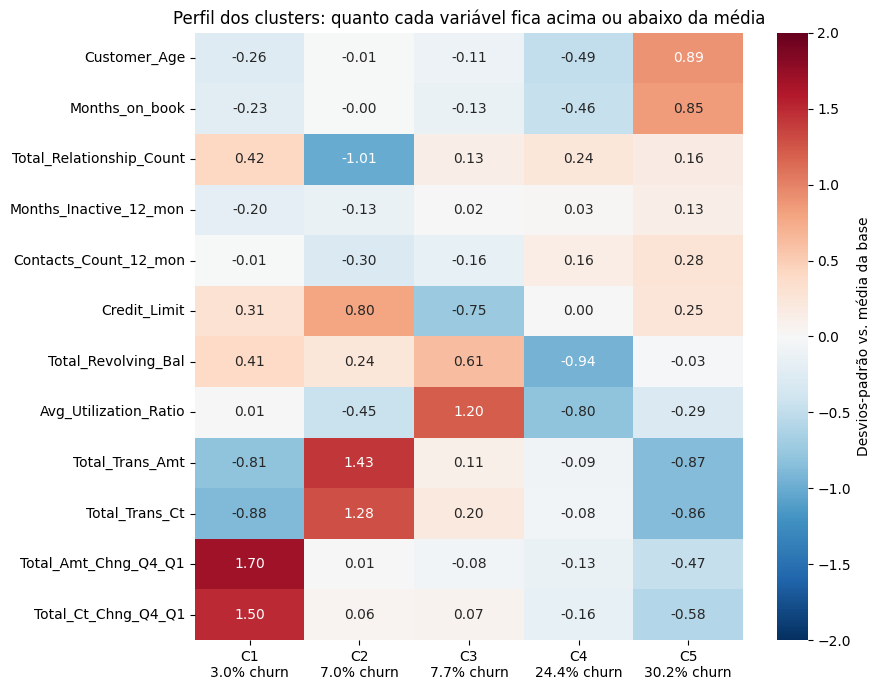

In [71]:
# Perfil: tamanho, cancelamento, participação nos cancelamentos e mediana das variáveis
perfil = df.assign(cancelou=cancelou).groupby("Cluster").agg(
    Clientes=("cancelou", "size"),
    **{"Cancelamento (%)": ("cancelou", lambda s: s.mean() * 100)},
    **{"% dos cancelamentos": ("cancelou", lambda s: s.sum() / cancelou.sum() * 100)},
)
perfil["% da base"] = perfil["Clientes"] / len(df) * 100
perfil = perfil[["Clientes", "% da base", "Cancelamento (%)", "% dos cancelamentos"]]
perfil = perfil.join(df.groupby("Cluster")[vars_cluster].median())

linhas_inteiras = ["Clientes", "Credit_Limit", "Total_Revolving_Bal", "Total_Trans_Amt"]
linhas_pct = ["% da base", "Cancelamento (%)", "% dos cancelamentos"]
display(
    perfil.T.style
    .format(precision=2)
    .format("{:,.0f}", subset=pd.IndexSlice[linhas_inteiras, :])
    .format("{:.1f}", subset=pd.IndexSlice[linhas_pct, :])
)

# Mapa de calor: média padronizada de cada variável por cluster
# (0 = média da base; positivo = acima; negativo = abaixo)
z_medio = X_scaled.groupby(df["Cluster"].to_numpy()).mean().T[ordem_clusters]
z_medio.columns = [f"{c}\n{perfil.loc[c, 'Cancelamento (%)']:.1f}% churn" for c in ordem_clusters]
limite_cor = np.ceil(z_medio.abs().max().max() * 2) / 2

plt.figure(figsize=(9, 7))
sns.heatmap(z_medio, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-limite_cor, vmax=limite_cor,
            cbar_kws={"label": "Desvios-padrão vs. média da base"})
plt.title("Perfil dos clusters: quanto cada variável fica acima ou abaixo da média")
plt.xlabel("")
plt.tight_layout()
plt.show()

### 6.2 Indicadores de comportamento e variáveis descritivas
Aqui entram as variáveis que **não** formaram os grupos: cartão, estado civil, escolaridade, sexo e renda. Elas servem só para descrevê-los. Sexo e renda devem ser lidos com a ressalva da seção 2.2: nenhuma mulher aparece com renda acima de US$ 60K.

In [72]:
cancelou_s = df["Attrition_Flag"].eq("Attrited Customer")

# Indicadores de comportamento (% de clientes de cada cluster)
indicadores_comp = pd.DataFrame({
    "Sem saldo rotativo": df["Total_Revolving_Bal"].eq(0),
    "4+ contatos no ano": df["Contacts_Count_12_mon"].ge(4),
    "3+ meses inativo": df["Months_Inactive_12_mon"].ge(3),
    "Gasto no 4º tri ≥ 1º tri": df["Total_Amt_Chng_Q4_Q1"].ge(1),
    "Gasto anual ≥ 11 mil": df["Total_Trans_Amt"].ge(11000),
})
tabela_comp = indicadores_comp.groupby(df["Cluster"]).mean().mul(100)
tabela_comp.loc["Base"] = indicadores_comp.mean().mul(100)
print("Indicadores de comportamento (% de clientes)")
display(tabela_comp.round(1))

# Variáveis descritivas (% de clientes de cada cluster)
for c in ["Card_Category", "Marital_Status", "Education_Level", "Gender", "Income_Category"]:
    tab = pd.crosstab(df["Cluster"], df[c], normalize="index").mul(100)
    tab.loc["Base"] = df[c].value_counts(normalize=True).mul(100)
    print(c + ("  (ressalva da seção 2.2)" if c in ["Gender", "Income_Category"] else ""))
    display(tab.round(1))

print("Média de dependentes:", df.groupby("Cluster")["Dependent_count"].mean().round(1).to_dict())

Indicadores de comportamento (% de clientes)


,Sem saldo rotativo,4+ contatos no ano,3+ meses inativo,Gasto no 4º tri ≥ 1º tri,Gasto anual ≥ 11 mil
Cluster,,,,,
C1,7.4,16.4,36.4,60.4,0.0
C2,14.2,4.9,39.6,4.0,43.1
C3,0.0,11.6,46.1,4.8,0.4
C4,63.4,20.4,46.9,6.5,0.2
C5,24.6,25.5,50.5,4.3,0.0
Base,24.4,16.0,45.3,9.9,7.4


Card_Category


Card_Category,Blue,Gold,Platinum,Silver
Cluster,,,,
C1,94.0,1.2,0.1,4.6
C2,79.1,4.5,0.8,15.5
C3,99.9,0.0,0.0,0.1
C4,94.6,0.6,0.1,4.7
C5,93.2,0.6,0.1,6.1
Base,93.2,1.1,0.2,5.5


Marital_Status


Marital_Status,Divorced,Married,Single,Unknown
Cluster,,,,
C1,6.4,60.2,27.1,6.2
C2,7.3,43.0,41.0,8.7
C3,7.6,44.5,40.4,7.5
C4,8.5,42.3,41.1,8.0
C5,6.1,50.5,37.4,6.0
Base,7.4,46.3,38.9,7.4


... (3 outputs left out)

Gender,F,M
Cluster,,
C1,38.2,61.8
C2,38.0,62.0
C3,73.6,26.4
C4,52.9,47.1
C5,42.7,57.3
Base,52.9,47.1


Income_Category  (ressalva da seção 2.2)


Income_Category,$120K +,$40K - $60K,$60K - $80K,$80K - $120K,Less than $40K,Unknown
Cluster,,,,,,
C1,9.7,16.2,19.1,20.9,23.2,10.8
C2,11.7,15.5,17.0,21.7,22.7,11.4
C3,2.1,20.5,8.0,6.8,53.3,9.2
C4,6.3,17.3,14.8,14.9,33.5,13.2
C5,10.5,16.6,15.8,19.2,27.4,10.4
Base,7.2,17.7,13.8,15.2,35.2,11.0


Média de dependentes: {'C1': 2.3, 'C2': 2.4, 'C3': 2.4, 'C4': 2.5, 'C5': 2.0}


**Leitura.**
- **Escolaridade** e número de **dependentes** quase não variam entre os clusters.
- **Estado civil** só se destaca em C1, com mais casados (60%, contra 46% na base).
- **Cartão:** C2 concentra os cartões Silver, Gold e Platinum (21%, contra 7% na base). C3 é praticamente só Blue.
- **Sexo e renda:** C3 tem 74% de mulheres e 53% com renda abaixo de US$ 40K. Pela inconsistência renda × sexo da base, isso deve ser lido com cuidado: a renda das mulheres parece subestimada.

### 6.3 Perfil de cada cluster

**C1 – Uso baixo, mas em crescimento** (888 clientes · 8,8% da base · cancelamento de **3,0%** · 1,7% dos cancelamentos)
- Gastam e transacionam pouco: mediana de 1.972 no ano e 42 transações.
- Diferente de todos os outros grupos, o uso **não caiu** no fim do ano: 60% gastaram no 4º trimestre pelo menos o mesmo que no 1º, contra 10% na base. As variações Q4/Q1 têm mediana ≈ 1,0 (valor e quantidade), contra ≈ 0,7 na base. É o traço mais forte do grupo no mapa de calor (+1,70 e +1,50 desvios). Os 169 clientes com variação acima de 1,5 estão todos aqui.
- Têm um pouco mais de produtos no banco (mediana de 5), usam algum rotativo e são mais frequentemente casados (60%).
- Ressalva: é o grupo com fronteiras mais difusas (silhueta ≈ 0,08).
- *Interpretação:* clientes de baixo uso, mas em fase de **retomada ou crescimento**. É o grupo de menor risco.

**C2 – Alto gasto, alto limite e pouco vínculo** (1.698 · 16,8% · **7,0%** · 7,3%)
- Maior gasto (mediana de 8.526 e 94 transações) e maior limite (11.418).
- Usam pouco do limite (10%).
- Têm **poucos produtos** no banco (mediana de 2, o menor de todos).
- Concentram os cartões Silver, Gold e Platinum (21%).
- É heterogêneo (6.3): quem gasta 11 mil ou mais não cancela, mas a faixa de 7 a 11 mil cancela ≈ 20%.
- *Interpretação:* clientes valiosos pelo uso do cartão, mas com **pouco vínculo** com o banco.

**C3 – Usuários intensos do limite (rotativo)** (2.872 · 28,4% · **7,7%** · 13,6%)
- Limite baixo (mediana de 2.616) e o **maior uso do limite** (61%).
- **Todos** carregam saldo rotativo de um mês para o outro (mediana de 1.647).
- Gasto e número de transações perto da média.
- Quase só cartão Blue; maioria de mulheres e de renda declarada abaixo de US$ 40K (com a ressalva da seção 2.2).
- *Interpretação:* clientes que **dependem do crédito** do cartão. Isso os prende ao banco (risco baixo) e pode gerar receita de juros. A rentabilidade, porém, **não é medida** nesta base: é uma hipótese a confirmar com dados financeiros.

**C4 – Sem saldo rotativo, mais jovens e mais recentes** (2.610 · 25,8% · **24,4%** · 39,2%)
- **63% não têm saldo rotativo** (a mediana é zero), e o uso do limite também fica em zero.
- Gasto e número de transações perto da média.
- São os **mais jovens** e com **menos tempo de casa** (mediana de 43 anos e 34 meses).
- Têm um pouco mais de contatos com o banco (mediana de 3, contra 2). Concentram mais da metade (29 de 54) dos clientes com 6 contatos no ano, que cancelaram todos.
- *Interpretação:* usam o cartão, mas **não dependem dele**. Pagam tudo, não têm vínculo de crédito e são relativamente novos. É fácil trocar de cartão.

**C5 – Veteranos em queda de uso** (2.059 · 20,3% · **30,2%** · 38,2%)
- Os **mais velhos e mais antigos** (mediana de 54 anos e 42 meses de casa).
- O **menor uso** do cartão (mediana de 1.840 e 41 transações).
- A **maior queda** do 4º para o 1º trimestre (variações de 0,65 e 0,57, as menores de todas).
- Ficam um pouco mais tempo inativos (mediana de 3 meses, contra 2) e procuram mais o banco (25% com 4 ou mais contatos no ano, contra 16% na base).
- Ressalva: fronteiras difusas (silhueta ≈ 0,07).
- *Interpretação:* clientes antigos que estão **se desligando do cartão aos poucos**. É o grupo de maior risco.

## Conclusão

Para esse escopo (base BankChurners, com 10.127 clientes de cartão de crédito), o K-Means com PCA segmentou a carteira em **5 perfis**. A segmentação usou o uso do cartão, o crédito, o relacionamento com o banco e a idade, **sem a informação de cancelamento**. O risco de cancelamento varia de **3,0% a 30,2%** entre os grupos (base: 16,1%). Os dois grupos de maior risco (**C4 e C5**) reúnem **46% dos clientes e 77% dos cancelamentos**.

| Cluster | Perfil | Cancelamento | Ação sugerida |
|---|---|---|---|
| **C1** | Uso baixo, mas em crescimento | 3,0% | Manutenção de baixo custo. Aproveitar a fase de crescimento com ofertas de uso, sem gastar com retenção. |
| **C2** | Alto gasto, alto limite, pouco vínculo | 7,0% | Venda cruzada de produtos para aumentar o vínculo. Atenção especial à faixa de gasto de 7 a 11 mil (≈ 20% de cancelamento). |
| **C3** | Usuários intensos do limite (rotativo) | 7,7% | Acompanhar o risco de crédito e rever o limite com cuidado. Validar a rentabilidade com dados de receita. |
| **C4** | Sem rotativo, mais jovens e recentes | 24,4% | Benefícios ligados ao uso (cashback, pontos, isenção de anuidade) para tornar o cartão o principal. Acompanhamento nos primeiros anos e atenção a quem procura muito o banco. |
| **C5** | Veteranos em queda de uso | 30,2% | Prioridade máxima: monitorar a queda de transações e fazer contato proativo antes da saída. |

Isso responde à problemática: tratar todos os clientes da mesma forma desperdiça recursos, e a retenção deve se concentrar em **C4 e C5** (e no subgrupo de 7 a 11 mil do C2).

**Limites da análise:**
- A silhueta é baixa (≈ 0,12). Os grupos são **estáveis**, mas têm fronteiras graduais, e devem ser lidos como **perfis predominantes**, não como grupos naturais.
- A base não informa **quando** cada cliente cancelou. Então os perfis estão **associados** ao cancelamento, mas não são preditores antecipados dele, e as ações sugeridas são **hipóteses** a validar (por exemplo, com testes controlados).
- Renda e sexo têm uma inconsistência na base (seção 2.2) e não foram usados para formar os grupos.